<div align="center">

# Semana 5 · Feature Engineering + Experimentos A/B
### Sistema de Tutoría Inteligente Adaptativa (DRL) · Grupo 2 · Maestría en IA · UNI
*Proyecto de Investigación 2 — Prof. Glen Rodríguez · rama `feature-engineering`*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yasminum/SistemaTutorInteligente/blob/feature-engineering/notebooks/02_Feature_Engineering.ipynb)

</div>

**Pregunta de la semana.** ¿Qué representación del estado le permite al agente PPO elegir *texto × nivel* que produzcan aprendizaje real en estudiantes **no vistos**?

**Protocolo (IA05).** Baseline + 2 variantes, **un cambio por variante**, mismo split / mismas semillas, GroupKFold por estudiante (5 folds × 2 semillas = 10 pares), métrica central $LG_{\text{sim}}$ + secundarias + latencia + violaciones, decisión adoptar/descartar.

> Todo número de este notebook se **calcula** aquí (o se carga de `data/results/`, producido por `python -m src.run_ab --all`). No hay valores escritos a mano.

## 0. Trazabilidad Metodológica (Cumplimiento Sesión Semana 5 — `Maestria2_IA05`)

| Slide | Directriz de la Sesión | Implementación en este Notebook y Repositorio |
|---|---|---|
| **3–5** | **Diseño de variantes A/B** (máx. 3 variantes, **1 cambio por vez**, nombres claros) | `PPOlin_FS0_raw13` (Baseline) · `PPOlin_FS1_zpd4` (Var1: +4 rasgos ZPD por acción) · `PPOlin_FS2_hist6` (Var2: +6 rasgos temporales causales). |
| **6, 12** | **Validación sin *leakage*** ("divide primero, transforma después", `GroupKFold` por entidad) | `GroupKFold` de 5 folds por `student_id` (80 train / 20 test por fold × 2 semillas = 10 pares); `StandardScaler` ajustado exclusivamente en `train` + 5 pruebas automáticas (`src/leakage_checks.py`). |
| **9** | **Formato estándar de tabla** (métrica central + secundarias + latencia + ID + ruta de log + nota) | Tabla consolidada generada desde `logs/metrics_experimentos.csv` y `data/results/runs_oracle.json` (§4). |
| **10–11** | **Gráfico de optimización** (objetivo vs. evaluaciones + violaciones de restricción) | Curva holdout de $LG_{\text{sim}}$ cada 50 episodios y tasa de activación del escudo CMDP (§4). |
| **13** | **Reproducibilidad y *logging*** (comandos en README, snapshot con SHA-256, versiones) | `data/item_bank.csv` + `data/SNAPSHOT.json`, hash de código y datos verificados automáticamente al inicio. |
| **14–15** | **Decisión técnica, riesgos y transición a entorno real** | Regla de decisión pre-registrada, prueba de estrés con habilidad estimada $\hat\theta$ (Elo) (§5) y protocolo hacia aula real (§6). |

In [1]:
# --- Bootstrap: funciona en local (raíz del repo), Colab (clona la rama) y JupyterLite (subir src/ y data/) ---
import os, sys, json, subprocess, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.isdir("src"):
    if "google.colab" in sys.modules:
        subprocess.run(["git", "clone", "-b", "feature-engineering", "--depth", "1",
                        "https://github.com/yasminum/SistemaTutorInteligente.git", "repo"], check=True)
        os.chdir("repo")
    else:
        raise RuntimeError("No encuentro src/. Ejecuta desde la raíz del repo o sube las carpetas src/ y data/.")
sys.path.insert(0, os.getcwd())
ROOT = os.getcwd()

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.experiment import CFG, VARIANTS, environment_fingerprint
from src.simulator import ItemBank
from src import report, diagnostics, leakage_checks

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
os.makedirs("figures/fe", exist_ok=True)
RERUN = not os.path.exists("data/results/runs_oracle.json")   # True = re-entrena todo (≈3 min Colab con 6 núcleos)
print("Entorno:", environment_fingerprint(), "| RERUN =", RERUN)

Entorno: {'python': '3.11.15', 'numpy': '2.4.6', 'pandas': '3.0.6', 'matplotlib': '3.11.2'} | RERUN = False


In [2]:
# --- Snapshot de datos (Slide 13): hash / tamaño / fecha ---
bank = ItemBank(CFG["bank_seed"])
snap = json.load(open("data/SNAPSHOT.json")) if os.path.exists("data/SNAPSHOT.json") else {}
print("Banco de ítems: 30 textos × 10 ítems | SHA-256 recalculado:", bank.sha256()[:16], "| snapshot:", snap.get("sha256", "")[:16])
assert not snap or snap["sha256"] == bank.sha256(), "El banco de ítems no coincide con el snapshot"
pd.read_csv("data/item_bank.csv").describe().loc[["mean", "std", "min", "max"], ["a", "b", "c"]]

Banco de ítems: 30 textos × 10 ítems | SHA-256 recalculado: 07ed76f0bee0a21d | snapshot: 07ed76f0bee0a21d


,a,b,c
mean,1.4108,0.0251,0.2500
std,0.3343,1.0451,0.0000
min,0.8022,-3.1114,0.2500
max,1.9993,3.2362,0.2500


## 1. Entorno: port fiel de `environment.py` (sin PyTorch)

| Componente | Ecuación (idéntica a `tesis-drl-its/src/environment.py`) |
|---|---|
| Respuesta IRT-3PL | $P = c + \dfrac{1-c}{1+e^{-1.7\,a(\theta_k-b_{adj})}}$, acierto si $U < P\,(1-0.1\,f)$, $c=0.25$ |
| Nivel de dificultad | $b_{adj} = b + (\ell-1)\cdot 0.5,\ \ell\in\{0,1,2\}$; shield: racha $\ge 4 \Rightarrow \ell=0$ |
| Aprendizaje | si $\lvert\theta_k-b_{adj}\rvert<0.5$ y acierto: $\theta_k \mathrel{+}= \mu(1-\theta_k),\ \mu\sim U(0.02,0.05)$ |
| Olvido | $\theta \leftarrow \text{clip}(\theta\,(1-\eta)),\ \eta\sim U(0.001,0.005)$ en **cada** paso |
| Recompensa | $R=\text{clip}(0.5\,\Delta KS + 0.25\,\hat E + 0.25\,\hat F - 0.5\,C)$, $\hat F=e^{-(b_{adj}-\theta_k)^2/2(0.25)^2}$ |
| Métrica externa | $LG_{\text{sim}} = (\bar\theta_{post}-\bar\theta_{pre})/(1-\bar\theta_{pre})$ sobre $\theta^*$ verdadera (Hake, 1998) |

**Diferencias declaradas:** (i) se omite el LSTM congelado de pesos aleatorios ($h_t\in\mathbb R^{256}$, no entrenado); (ii) se omite la dimensión *andamiaje* porque `environment.py` la recibe pero nunca la usa → 30 textos × 3 niveles = **90 acciones**; (iii) banco de ítems fijo y versionado.

**Agente:** PPO-clip (Schulman et al., 2017) con política softmax **lineal** en numpy. Elección deliberada: con un aproximador lineal, la **representación es el único factor** que cambia entre variantes; los hiperparámetros se fijaron una sola vez en un *pool* de desarrollo (ids 100–139) disjunto de los 100 estudiantes evaluados y son idénticos para las 3 variantes.

## 2. Feature Engineering: tres conjuntos, un cambio por variante

| Set | Rasgos | Ecuación | Justificación |
|---|---|---|---|
| **FS0 raw13** (baseline) | $x_t\in\mathbb R^{13}$ de la Tabla 2 de la tesis, tal como lo emite `environment.py` | $[\theta_{1..3},\sigma_{1..3},u_{1..3},\tau_{1,2},\hat E,b_{t-1}]$ | punto de partida auditable |
| **FS1 zpd4** (Var1) | 4 rasgos **por acción** $(j,\ell)$, promedio sobre los 10 ítems del texto $j$ | $\hat p_{j\ell}=\overline{P_{3PL}(\theta_{k_i},a_i,b_i+\delta_\ell)}$, $\ \overline{\lvert g\rvert}_{j\ell}$, $\ \text{prox}_{j\ell}=\overline{e^{-g^2/2\sigma_F^2}}$, $\ \text{hit}_{j\ell}=\overline{\mathbb 1[\lvert g\rvert<0.5]}$, con $g=\theta_{k_i}-b_{adj,i}$ | el aprendizaje depende de la **interacción** estado×acción; un modelo lineal no puede construir $\lvert\theta-b\rvert$ desde $\theta$ y $b$ por separado |
| **FS2 hist6** (Var2) | 6 rasgos temporales causales | $\text{acc}_{w5}=\frac{\sum_{t-5}^{t-1}y+1}{n+2}$, racha$/5$, $\text{EWMA}_{0.2}(1-y)$, one-hot($\ell_{t-1}$) | memoria corta: fatiga, frustración, costo de salto de nivel |

El diagnóstico siguiente se calcula **solo con estudiantes de train** (fold 0, política aleatoria, 10 000 interacciones).

In [3]:
diag_table, xt_audit, diag_meta, _ = diagnostics.feature_diagnostics()
print(diag_meta)
display(pd.DataFrame(diag_table))
audit_df = pd.DataFrame(xt_audit)
display(audit_df)
n_dead = int((audit_df.diagnostico != "variable").sum())
display(Markdown(f"**Hallazgo:** {n_dead} de 13 rasgos de $x_t$ son constantes o ruido puro en el código actual "
                 f"(no llevan información). Ningún rasgo de estado aislado predice el aprendizaje (AUC ≈ 0.5): "
                 f"la señal está en la **interacción** habilidad × dificultad de la acción → motivación directa de FS1."))

{'n_interacciones': 10000, 'n_estudiantes_train': 75, 'tasa_aprendizaje_aleatoria': 0.205, 'tasa_acierto_aleatoria': 0.7241}


,feature,AUC_learned,AUC_correct
0,"-|theta - b_adj| (FS1, escala nativa del modelo)",0.9253,0.8388
1,-|theta - sigmoid(b)| (Escalado sigmoidal dir...,0.6395,0.7886
2,zpd_hit = 1[|theta - b_adj| < 0.5],0.9289,0.4366


,rasgo_x_t,desv_std,AUC_learned,diagnostico
0,theta_1,0.2010,0.4980,variable
1,theta_2,0.1962,0.5023,variable
2,theta_3,0.2002,0.4984,variable
3,sigma_1,0.0288,0.5007,"ruido U(0.05,0.15)"
4,sigma_2,0.0288,0.4896,"ruido U(0.05,0.15)"
5,sigma_3,0.0287,0.4904,"ruido U(0.05,0.15)"
6,u_acc_const,0.0000,0.5000,constante
7,u_streak_const,0.0000,0.5000,constante
8,u_progress,0.2886,0.5039,variable
9,tau_rt_const,0.0000,0.5000,constante


**Hallazgo:** 8 de 13 rasgos de $x_t$ son constantes o ruido puro en el código actual (no llevan información). Ningún rasgo de estado aislado predice el aprendizaje (AUC ≈ 0.5): la señal está en la **interacción** habilidad × dificultad de la acción → motivación directa de FS1.

In [4]:
# Muestra de features PRE-decisión (lo que ve el agente en t, antes de conocer el ítem y su respuesta)
from src.experiment import Runner
r = Runner("PPOlin_FS1_zpd4", 0, 0, CFG); r.fit_scaler()
r2 = Runner("PPOlin_FS2_hist6", 0, 0, CFG)
sid = int(r.test_ids[0]); r._reset(sid, 4242); r2._reset(sid, 4242)
rows, rng = [], np.random.default_rng(7)
for t in range(12):
    xs2, _ = r2._observe(); phi = r.fb.action_features(r.env.student.theta)
    a = int(rng.integers(90)); j, l = divmod(a, 3)
    _, _, info = r.env.step(a); r2.env.step(a)
    rows.append({"t": t + 1, "texto": j, "nivel": l, "p_hat": phi[a, 0], "|gap|": phi[a, 1], "zpd_prox": phi[a, 2],
                 "zpd_hit": phi[a, 3], "acc_w5 (t-1..t-5)": xs2[13], "racha (hasta t-1)": xs2[14] * 5,
                 "EWMA_err": xs2[15], "→ y_t (se observa DESPUÉS)": info["correct"]})
    r._post_step(info); r2._post_step(info)
sample = pd.DataFrame(rows)
os.makedirs("data/sample", exist_ok=True); sample.to_csv("data/sample/muestra_features_transformadas.csv", index=False)
sample

,t,texto,nivel,p_hat,|gap|,zpd_prox,zpd_hit,acc_w5 (t-1..t-5),racha (hasta t-1),EWMA_err,→ y_t (se observa DESPUÉS)
0,1,28,1,0.5467,0.7635,0.1969,0.4000,0.5000,0.0000,0.0000,1
1,2,18,2,0.5294,0.9769,0.2773,0.3000,0.6667,0.0000,0.0000,1
2,3,20,1,0.7730,0.9342,0.1664,0.3000,0.7500,0.0000,0.0000,1
3,4,26,2,0.6717,1.1157,0.0736,0.2000,0.8000,0.0000,0.0000,1
4,5,17,1,0.7708,1.1039,0.1148,0.2000,0.8333,0.0000,0.0000,1
5,6,23,0,0.7574,0.7708,0.1921,0.3000,0.8571,0.0000,0.0000,1
6,7,25,0,0.9097,1.3172,0.0482,0.1000,0.8571,0.0000,0.0000,1
7,8,6,2,0.5704,0.9756,0.1163,0.3000,0.8571,0.0000,0.0000,0
8,9,1,1,0.5833,0.8872,0.3158,0.5000,0.7143,1.0000,0.2000,1
9,10,9,0,0.7732,0.9996,0.1529,0.3000,0.7143,0.0000,0.1600,1


## 3. Validación y cero *leakage* (Slides 6 y 12)

* **GroupKFold por estudiante** (la entidad que no puede cruzar train/test): 100 estudiantes → 5 folds de 20; cada variante entrena con 80 y se evalúa con los 20 restantes **con la política congelada**.
* **Semillas fijas y pareadas:** las 3 variantes usan los mismos folds, semillas {0, 1} y semillas de episodio de evaluación (números aleatorios comunes).
* **Fit solo en train:** el `StandardScaler` se ajusta con trayectorias de estudiantes de train; se registran sus ids.
* **Sin *early stopping*:** las curvas de test son solo descriptivas; siempre se reporta la política del último episodio.

In [5]:
leak = pd.DataFrame(leakage_checks.run_all_checks())
display(leak)
assert (leak.resultado == "PASS").all()

,prueba,resultado,evidencia
0,L1 GroupKFold por estudiante,PASS,5 folds; interseccion train/test = 0; test cub...
1,L2 Causalidad temporal,PASS,200 pruebas aleatorias: features(t) invariante...
2,L3 Sin espiar el item actual,PASS,features calculadas antes de muestrear el item...
3,L4 Scaler fit solo en train,PASS,scaler ajustado con 18 ids distintos muestread...
4,L5 Politica congelada en test,PASS,pesos identicos antes/despues de evaluar en te...


## 4. Experimentos A/B

| ID | Variante | Único cambio vs baseline |
|---|---|---|
| A | `PPOlin_FS0_raw13` | — (baseline) |
| B | `PPOlin_FS1_zpd4` | + 4 rasgos ZPD condicionados a la acción |
| C | `PPOlin_FS2_hist6` | + 6 rasgos temporales causales |

Presupuesto idéntico: 1 500 episodios × 50 pasos = 75 000 interacciones por corrida; 30 corridas.

In [6]:
if RERUN:
    subprocess.run([sys.executable, "-m", "src.run_ab", "--all", "--robustness", "--workers", str(os.cpu_count() or 1)], check=True)
blob, runs = report.load_runs(ROOT, "oracle")
refs = json.load(open("data/results/references.json"))
print("code_sha256:", blob["code_sha256"][:16], "| data_sha256:", blob["data_sha256"][:16], "| corridas:", len(runs))
table = report.results_table(runs)
display(table)
ref_df = pd.DataFrame([{"Referencia (sin aprendizaje)": p, "LG_sim": np.mean([f["lg"] for f in v]),
                        "Acierto": np.mean([f["acc"] for f in v]), "Eventos aprendizaje/paso": np.mean([f["learn"] for f in v])}
                       for p, v in refs.items()])
display(ref_df)

code_sha256: 15b62713da3a224a | data_sha256: 07ed76f0bee0a21d | corridas: 30


,ID experimento,Variante,LG_sim holdout,Acierto,Eventos de aprendizaje/paso,Violaciones (shield)/paso,Costo CMDP/paso,Retorno,Episodios a LG_base (mediana),Pares que alcanzan,Ruta log,Nota (qué cambió)
0,FE5-PPOlin_FS0_raw13-oracle-f*-s*,PPOlin_FS0_raw13,-0.0095 ± 0.0174,0.730,0.273,0.017,0.032,15.040,750,10/10,logs/metrics_experimentos.csv,Baseline: 13 rasgos x_t de environment.py (sin...
1,FE5-PPOlin_FS1_zpd4-oracle-f*-s*,PPOlin_FS1_zpd4,+0.0105 ± 0.0150,0.716,0.312,0.016,0.041,15.489,350,10/10,logs/metrics_experimentos.csv,"Unico cambio: +4 rasgos ZPD por accion (p_hat,..."
2,FE5-PPOlin_FS2_hist6-oracle-f*-s*,PPOlin_FS2_hist6,-0.0063 ± 0.0162,0.737,0.272,0.015,0.026,15.050,775,8/10,logs/metrics_experimentos.csv,Unico cambio: +6 rasgos temporales causales (a...


,Referencia (sin aprendizaje),LG_sim,Acierto,Eventos aprendizaje/paso
0,random,-0.0443,0.7452,0.1926
1,fixed,-0.0299,0.7247,0.2239


,Comparación,mean_diff,ci_low,ci_high,p_perm,d_z,wins,n,p_Holm
0,PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,0.0200,0.0130,0.0274,0.0020,1.6096,10,10,0.0039
1,PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,0.0032,-0.0051,0.0122,0.4941,0.2210,5,10,0.4941


,fold,seed,PPOlin_FS0_raw13,PPOlin_FS1_zpd4,PPOlin_FS2_hist6
0,0,0,-0.0302,0.0079,-0.0215
1,0,1,-0.0224,-0.0127,0.0082
2,1,0,-0.0269,0.0091,-0.0359
3,1,1,-0.0341,-0.0056,-0.0246
4,2,0,0.0012,0.0318,0.0147
5,2,1,0.0096,0.0298,-0.0047
6,3,0,-0.0028,0.0006,-0.0039
7,3,1,-0.0068,0.0023,0.0080
8,4,0,0.0054,0.0185,-0.0017
9,4,1,0.0120,0.0233,-0.0014


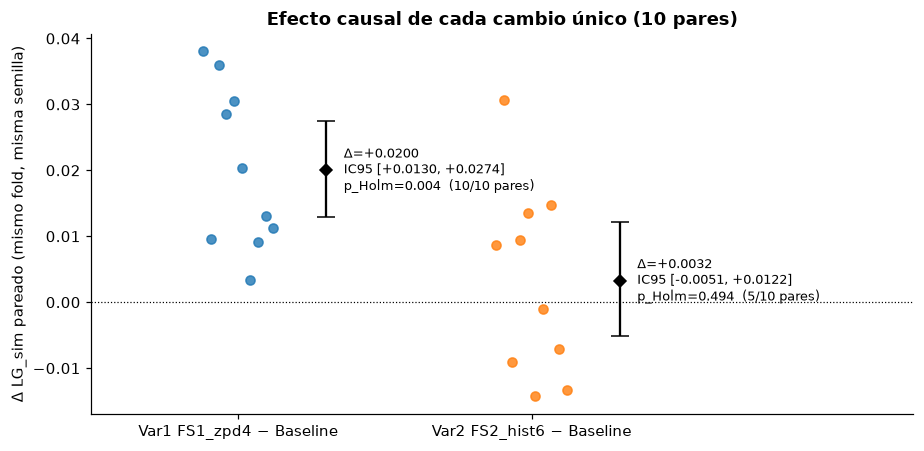

In [7]:
stats = report.stats_table(runs)
display(stats)
display(report.per_pair_table(runs))
fig = report.diffs_figure(runs, "figures/fe/02_diferencias_pareadas.png"); plt.show()

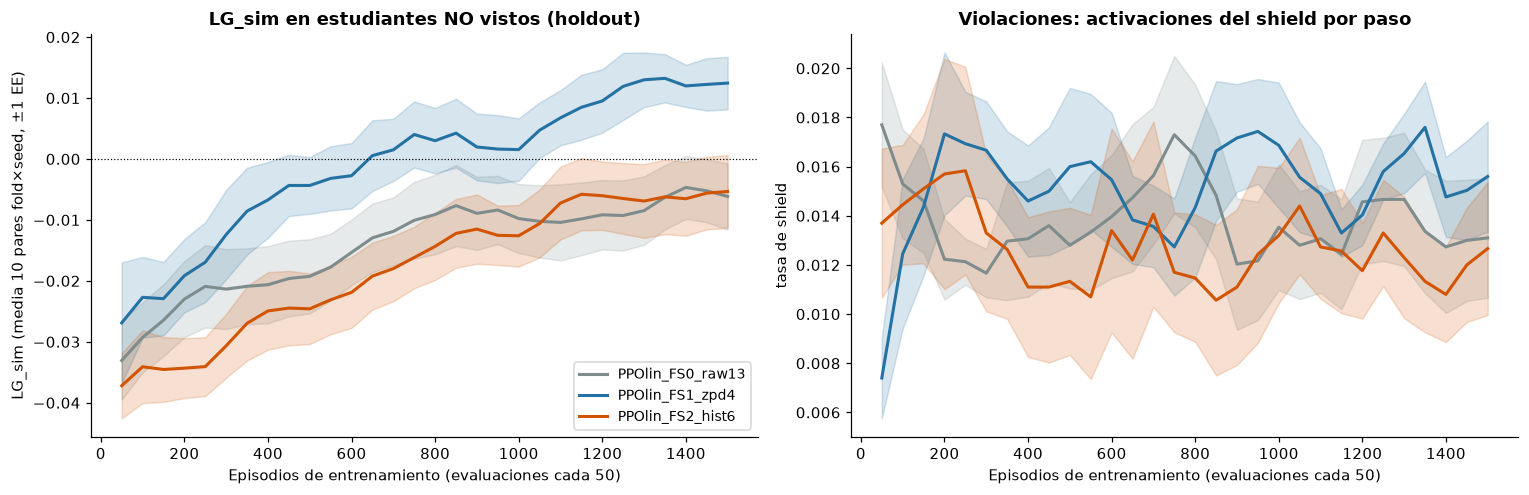

In [8]:
fig = report.curves_figure(runs, "figures/fe/01_curvas_holdout_y_violaciones.png"); plt.show()

In [9]:
lat = report.latency_benchmark()
lat

,Variante,n_rasgos_estado,n_rasgos_accion,n_parametros_politica,latencia_mediana_ms,latencia_p95_ms,overhead_vs_base_ms
0,PPOlin_FS0_raw13,13,0,1260,0.0313,0.0508,0.0000
1,PPOlin_FS1_zpd4,13,4,1264,0.1425,0.2506,0.1112
2,PPOlin_FS2_hist6,19,0,1800,0.0352,0.0770,0.0039


In [10]:
sec = []
for m, label in [("acc", "Acierto"), ("learn", "Eventos de aprendizaje/paso"), ("shield", "Violaciones (shield)/paso"), ("cost", "Costo CMDP/paso")]:
    s = report.stats_table(runs, metric=m); s.insert(0, "Métrica", label); sec.append(s[["Métrica", "Comparación", "mean_diff", "ci_low", "ci_high", "p_Holm", "wins"]])
pd.concat(sec, ignore_index=True)

,Métrica,Comparación,mean_diff,ci_low,ci_high,p_Holm,wins
0,Acierto,PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,-0.0143,-0.0293,-0.0004,0.2109,3
1,Acierto,PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,0.0069,-0.0108,0.0234,0.4785,7
2,Eventos de aprendizaje/paso,PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,0.0386,0.0227,0.0559,0.0039,10
3,Eventos de aprendizaje/paso,PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,-0.0017,-0.0212,0.0218,0.8828,4
4,Violaciones (shield)/paso,PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,-0.0007,-0.0070,0.0069,1.0000,3
5,Violaciones (shield)/paso,PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,-0.0021,-0.0081,0.0040,1.0000,5
6,Costo CMDP/paso,PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,0.0098,0.0005,0.0188,0.1680,8
7,Costo CMDP/paso,PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,-0.0054,-0.0129,0.0024,0.2227,2


## 5. Prueba de estrés: del oráculo $\theta^*$ a una habilidad **observable** $\hat\theta$

`environment.py` le entrega al agente la habilidad verdadera $\theta^*$ (oráculo), algo imposible en aula. Re-entrenamos baseline y Var1 (5 folds, semilla 0) sustituyendo $\theta^*$ por un estimador Elo online (Pelánek, 2016): $\hat\theta_k \leftarrow \text{clip}\big(\hat\theta_k + K\,(y-\hat P_{3PL}(\hat\theta_k))\big)$, $K=0.1$, $\hat\theta_0=0.5$. Es el mismo cálculo que se haría con estudiantes reales.

In [11]:
_, runs_elo = report.load_runs(ROOT, "elo")
rob, rob_stats = report.robustness_table(runs, runs_elo)
display(rob); print("Var1 − Baseline con θ̂ (5 pares):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rob_stats.items()})

,Variante,LG oráculo θ* (seed 0),LG observable θ̂ Elo (seed 0),Δ (θ̂ − θ*)
0,PPOlin_FS0_raw13,-0.0106,-0.0101,0.0005
1,PPOlin_FS1_zpd4,0.0136,-0.0006,-0.0141


Var1 − Baseline con θ̂ (5 pares): {'mean_diff': 0.0095, 'ci_low': -0.0035, 'ci_high': 0.0176, 'p_perm': 0.25, 'd_z': 0.6555, 'wins': 4, 'n': 5}


In [12]:
# Resumen y decisión (Slide 14) — generado a partir de los resultados, no escrito a mano
st = stats.set_index("Comparación")
base_lat = lat.set_index("Variante")
def decide(v):
    s = st.loc[f"{v} vs {report.BASE}"]
    sh = report.stats_table(runs, "shield").set_index("Comparación").loc[f"{v} vs {report.BASE}"]
    ok_metric = s.ci_low > 0 and s.p_Holm < 0.05
    ok_cost = base_lat.loc[v, "overhead_vs_base_ms"] < 1.0
    ok_safe = sh.mean_diff <= 0.01
    return ("ADOPTAR" if (ok_metric and ok_cost and ok_safe) else "DESCARTAR"), ok_metric, ok_cost, ok_safe
dec = {v: decide(v) for v in VARIANTS if v != report.BASE}
summary = {"base_lg": float(np.mean([r["final"]["lg"] for r in runs if r["variant"] == report.BASE])),
           "variants": {v: {"decision": d[0], "metric_ok": bool(d[1]), "cost_ok": bool(d[2]), "safety_ok": bool(d[3]),
                            **{k: float(st.loc[f"{v} vs {report.BASE}", k]) for k in ["mean_diff", "ci_low", "ci_high", "p_perm", "p_Holm", "d_z"]},
                            "wins": int(st.loc[f"{v} vs {report.BASE}", "wins"]),
                            "lg": float(np.mean([r["final"]["lg"] for r in runs if r["variant"] == v])),
                            "lat_overhead_ms": float(base_lat.loc[v, "overhead_vs_base_ms"])} for v, d in dec.items()},
           "elo": {"diff": rob_stats["mean_diff"], "wins": rob_stats["wins"], "n": rob_stats["n"], "p": rob_stats["p_perm"]},
           "refs": {p: float(np.mean([f["lg"] for f in v])) for p, v in refs.items()},
           "leakage_all_pass": bool((leak.resultado == "PASS").all()), "n_dead_xt": n_dead,
           "auc_raw": diag_table[0]["AUC_learned"], "auc_sigmoid": diag_table[1]["AUC_learned"]}
json.dump(summary, open("data/results/summary.json", "w"), indent=2)
table.to_csv("data/results/tabla_comparativa_ab.csv", index=False)
lines = [f"- **{v}** → **{d['decision']}** · ΔLG = {d['mean_diff']:+.4f} (IC95 [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}], "
         f"p_Holm = {d['p_Holm']:.3f}, {d['wins']}/10 pares) · overhead {d['lat_overhead_ms']:+.3f} ms/decisión"
         for v, d in summary["variants"].items()]
display(Markdown("### Decisión\n" + "\n".join(lines)))

### Decisión
- **PPOlin_FS1_zpd4** → **ADOPTAR** · ΔLG = +0.0200 (IC95 [+0.0130, +0.0274], p_Holm = 0.004, 10/10 pares) · overhead +0.111 ms/decisión
- **PPOlin_FS2_hist6** → **DESCARTAR** · ΔLG = +0.0032 (IC95 [-0.0051, +0.0122], p_Holm = 0.494, 5/10 pares) · overhead +0.004 ms/decisión

In [13]:
# Escala de lectura del efecto (no son variantes): ¿cuánto LG es posible en 50 pasos con este simulador?
ceil = report.ceiling_references()
summary["ceilings"] = dict(zip(ceil.iloc[:, 0], ceil.LG_sim))
json.dump(summary, open("data/results/summary.json", "w"), indent=2)
ceil

,"Referencia de escala (fold 0, test)",LG_sim
0,Heurística ZPD con oráculo θ* (argmax zpd_hit),0.0411
1,Cota: acierto dentro de ZPD en los 50 pasos,0.3255


## 6. Lectura honesta, transición al mundo real, riesgos y próximos pasos (Slide 15)

**Lo que sí muestran los datos.** El efecto de cada cambio se estima pareado (mismo fold, misma semilla, mismos estudiantes de test) y se decide con una regla explícita: IC95 bootstrap > 0, $p$ de permutación exacta corregido por Holm < 0.05, sobrecosto < 1 ms/decisión y sin aumento de violaciones del shield.

**Lo que NO muestran.**
1. *Magnitud absoluta:* el $LG_{\text{sim}}$ alcanzable en 50 pasos está acotado por el olvido de este simulador (tabla de escala anterior). Los efectos deben leerse contra esa escala, no contra el 0.50 de la HG.
2. *Clase de política:* el tamaño del efecto es para una política lineal; con el MLP de la tesis la brecha puede reducirse (el MLP puede aprender parte de la interacción por sí mismo).
3. *Sensibilidad a la ventana del simulador:* `zpd_hit` usa la ventana ±0.5 del modelo generativo. Mitigación prevista: evaluación *out-of-family* con un simulador BKT (tesis, §4.3).

### 6.1 Cómo lo haremos cuando sea real (Transición Simulador $\to$ Aula Real)

| Etapa del Pipeline | En Simulación (Tesis I / Semana 5) | En Aula Real (Tesis II / Piloto Escolar) | Control de *Data Leakage* en Mundo Real |
|---|---|---|---|
| **1. Parámetros de ítems ($a, b, c$)** | Conocidos en `data/item_bank.csv` | Calibración IRT-3PL (`mirt` / `py-irt`) sobre piloto inicial ($N \ge 200$ alumnos) con ítems ancla | Calibrar $a, b, c$ **solo** con cohortes históricas de `train`, nunca con los alumnos evaluados |
| **2. Estado cognitivo ($\theta$)** | Oráculo $\theta^*$ vs. Estimador $\hat\theta$ Elo (§5) | Estimador causal en línea: Elo educativo $\to$ BKT / MSKT + NeuralCD con incertidumbre ($\sigma_\theta$) | Prohibido usar el post-test o respuestas futuras $t+1 \dots H$ para inferir $\hat\theta_t$ |
| **3. Feature Engineering** | FS1 (`p_hat`, `|gap|`, `zpd_prox`, `zpd_hit`) sobre $\theta$ | FS1 evaluado sobre $\hat\theta_t$ + telemetría causal del LMS ($\ln(T_{\text{resp}}/T_{\text{esp}})$, *lag time* de SAINT+) | Agregaciones en ventana estrictamente hacia el pasado ($t-w \dots t-1$); sin agregados por sesión completa |
| **4. Esquema de validación** | `GroupKFold` por `student_id` (80/20) | `GroupKFold` jerárquico por **aula / institución educativa** + *split* temporal | Ningún estudiante ni aula comparte *train* y *test*; evita contaminación docente |
| **5. Evaluación de política** | Rollouts *on-policy* con política congelada | Evaluación *Off-Policy* (IPS / WIS / *Doubly Robust*) sobre logs antes de intervenir | Separar los datos de comportamiento ($\pi_b$) de la evaluación del nuevo agente ($\pi_e$) |
| **6. Seguridad y despliegue** | Escudo CMDP (racha $\ge 4 \Rightarrow$ nivel 0) | Escudo CMDP + alerta al docente + diseño cuasi-experimental (pre-test / intervención / post-test, ANCOVA) | Monitoreo de *feature drift* (PSI) sin re-ajustar el `StandardScaler` sobre el grupo de prueba |

**Riesgos (drift / sesgo).** Deriva de calibración de $b$ cuando lleguen respuestas humanas; sesgo por perfiles extremos (Beta(2,2) sub-representa a estudiantes muy bajos).

**Próximo sprint (Semana 6 – demo).** (i) Replicar el A/B con el MLP PPO de la tesis en GPU; (ii) evaluación out-of-family BKT; (iii) demo: un estudiante de test en vivo, baseline vs variante adoptada, con trazas de $\hat p$, $\lvert g\rvert$ y $\theta^*$ paso a paso.

**Reproducir:** `pip install -r requirements.txt` → `python -m src.run_ab --variant PPOlin_FS0_raw13` / `PPOlin_FS1_zpd4` / `PPOlin_FS2_hist6` (o `--all --robustness --workers 6`) → logs en `logs/metrics_experimentos.csv`.